# Customer Churn & Retention Analysis

### Understanding customer behaviour, retention drivers, and recurring revenue at risk

**Project type:** Exploratory Data Analysis & Business Analytics  
**Dataset:** IBM Telco Customer Churn  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, SQLite, Jupyter Notebook

---

## 1. Business Objective

A subscription business can lose recurring revenue when customers cancel their services. The objective of this analysis is to understand **who is churning, when churn is most likely to occur, which subscription and service patterns are associated with churn, and where the greatest recurring-revenue risk exists**.

The analysis is designed to answer four business questions:

1. **Who is churning?** — identify customer segments with elevated churn.
2. **When are customers churning?** — examine tenure and lifecycle patterns.
3. **What is associated with churn?** — compare contracts, services, payments and customer characteristics.
4. **What is the financial exposure?** — quantify the recurring monthly charges associated with churned customers.

The goal is to turn descriptive analysis into **actionable retention recommendations**, while avoiding claims of causation where the dataset only shows associations.

## 2. Analytical Approach

**Raw data → quality audit → cleaning → SQLite analytical layer → KPI layer → segmentation → churn analysis → revenue-risk analysis → business recommendations**


In [1]:
import warnings
warnings.filterwarnings("ignore")

import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid", context="notebook")

In [2]:
DATA_PATH = Path("data/IBM_Telco_Customer_Churn.csv")
df_raw = pd.read_csv(DATA_PATH)

print(f"Dataset shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
display(df_raw.head())

Dataset shape: 7,043 rows × 33 columns


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.96,-118.27,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.06,-118.31,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.05,-118.29,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.06,-118.32,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.04,-118.27,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


## 3. Data Dictionary — Analytical Fields

| Field | Business meaning |
|---|---|
| `CustomerID` | Unique customer identifier |
| `Gender` | Customer gender |
| `Senior Citizen` | Senior-citizen indicator |
| `Partner` | Whether the customer has a partner |
| `Dependents` | Whether the customer has dependents |
| `Tenure Months` | Customer tenure in months |
| `Internet Service` | Internet service type |
| `Contract` | Contract duration |
| `Payment Method` | Payment method |
| `Monthly Charges` | Current monthly recurring charge |
| `Total Charges` | Charges accumulated during tenure |
| `Churn Label` | Whether the customer churned |
| `Churn Reason` | Recorded reason for churn |
| `CLTV` / `Churn Score` | Source-derived fields; excluded from driver inference |

`Count` and `Country` are constant in this extract and therefore provide no analytical variation.

## 4. Data Quality Audit

Before analysis we check duplicate customer IDs, missing values, inconsistent/blank values, data types, constant columns, and categorical distributions.

In [3]:
quality = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "missing": df_raw.isna().sum(),
    "missing_pct": df_raw.isna().mean().mul(100),
    "unique_values": df_raw.nunique(dropna=False)
}).sort_values(["missing", "unique_values"], ascending=[False, True])

display(quality)
print("Duplicate CustomerID records:", df_raw["CustomerID"].duplicated().sum())
print("Blank Total Charges values:", df_raw["Total Charges"].astype(str).str.strip().eq("").sum())
constant_cols = [c for c in df_raw.columns if df_raw[c].nunique(dropna=False) <= 1]
print("Constant columns:", constant_cols)

,dtype,missing,missing_pct,unique_values
Churn Reason,str,5174,73.46,21
Count,int64,0,0.00,1
Country,str,0,0.00,1
State,str,0,0.00,1
Gender,str,0,0.00,2
Senior Citizen,str,0,0.00,2
Partner,str,0,0.00,2
Dependents,str,0,0.00,2
Phone Service,str,0,0.00,2
Paperless Billing,str,0,0.00,2


Duplicate CustomerID records: 0
Blank Total Charges values: 11
Constant columns: ['Count', 'Country', 'State']


### Data-quality findings

The source contains 7,043 customer records. `Churn Reason` is naturally missing for retained customers because a reason is recorded only for customers labelled as churned.

`Total Charges` is stored as text and contains blank values. These blanks are converted to numeric missing values rather than being silently treated as zero.

`Count` and `Country` are constant and are removed. `Churn Score` and `CLTV` are source-derived fields, so they are not used to claim that a characteristic causes churn.

In [4]:
df = df_raw.copy()

df["Total Charges"] = pd.to_numeric(
    df["Total Charges"].replace(r"^\s*$", np.nan, regex=True),
    errors="coerce"
)

df = df.drop(columns=["Count", "Country"])

before = len(df)
df = df.drop_duplicates(subset="CustomerID").copy()

df["Churn Flag"] = df["Churn Label"].eq("Yes").astype(int)
df["Retention Flag"] = df["Churn Label"].eq("No").astype(int)

df["Revenue at Risk"] = np.where(
    df["Churn Flag"].eq(1),
    df["Monthly Charges"],
    0
)

df["Tenure Band"] = pd.cut(
    df["Tenure Months"],
    bins=[-1, 6, 12, 24, 48, 72],
    labels=["0–6 months", "7–12 months", "13–24 months", "25–48 months", "49–72 months"]
)

print(f"Rows before cleaning: {before:,}")
print(f"Rows after cleaning:  {len(df):,}")
print(f"Duplicate customer records removed: {before - len(df)}")
print(f"Missing Total Charges after conversion: {df['Total Charges'].isna().sum()}")

Rows before cleaning: 7,043
Rows after cleaning:  7,043
Duplicate customer records removed: 0
Missing Total Charges after conversion: 11


## 5. SQLite Analytical Layer

The cleaned customer table is loaded into a local SQLite database. This provides a practical SQL layer alongside Pandas and keeps the project self-contained without requiring an external database server.

In [5]:
db_path = Path("churn_analysis.sqlite")
conn = sqlite3.connect(db_path)
df.to_sql("customers", conn, if_exists="replace", index=False)

display(pd.read_sql_query("SELECT COUNT(*) AS customer_count FROM customers;", conn))

,customer_count
0,7043


## 6. Executive KPI Snapshot

The first analytical layer establishes the scale of the retention problem.

`Revenue at risk` is defined as the current monthly charge of customers labelled as churned. It is an exposure measure, **not a forecast of future lost revenue**.

In [6]:
total_customers = len(df)
churned_customers = int(df["Churn Flag"].sum())
retained_customers = int(df["Retention Flag"].sum())
churn_rate = df["Churn Flag"].mean()
retention_rate = df["Retention Flag"].mean()
mrr = df["Monthly Charges"].sum()
monthly_revenue_at_risk = df.loc[df["Churn Flag"].eq(1), "Monthly Charges"].sum()
avg_monthly_charge = df["Monthly Charges"].mean()
avg_tenure = df["Tenure Months"].mean()

kpis = pd.DataFrame({
    "Metric": [
        "Total Customers", "Churned Customers", "Retained Customers",
        "Churn Rate", "Retention Rate", "Current Monthly Charges",
        "Monthly Charges at Risk", "Average Monthly Charge", "Average Tenure"
    ],
    "Value": [
        f"{total_customers:,}", f"{churned_customers:,}", f"{retained_customers:,}",
        f"{churn_rate:.1%}", f"{retention_rate:.1%}", f"${mrr:,.2f}",
        f"${monthly_revenue_at_risk:,.2f}", f"${avg_monthly_charge:,.2f}",
        f"{avg_tenure:.1f} months"
    ]
})
display(kpis)

,Metric,Value
0,Total Customers,"7,043"
1,Churned Customers,"1,869"
2,Retained Customers,"5,174"
3,Churn Rate,26.5%
4,Retention Rate,73.5%
5,Current Monthly Charges,"$456,116.60"
6,Monthly Charges at Risk,"$139,130.85"
7,Average Monthly Charge,$64.76
8,Average Tenure,32.4 months


## 7. Churn Overview

The overall churn rate is useful context, but it is not sufficient for a retention strategy. The following sections break churn down by lifecycle, contract, services, payment behaviour, demographics, geography, and recorded churn reasons.

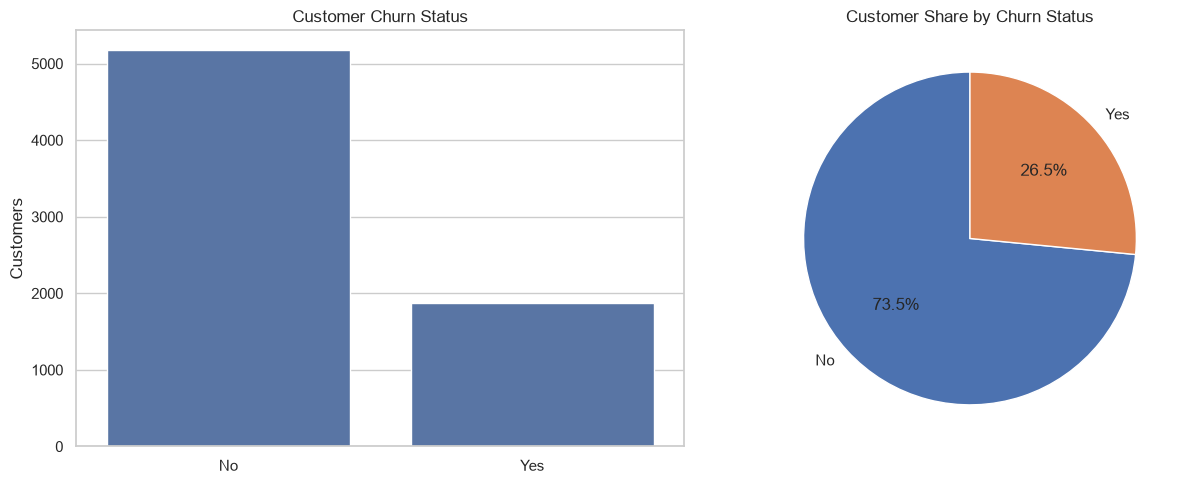

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

churn_counts = df["Churn Label"].value_counts()
sns.barplot(x=churn_counts.index, y=churn_counts.values, ax=axes[0], color="C0")
axes[0].set_title("Customer Churn Status")
axes[0].set_xlabel("")
axes[0].set_ylabel("Customers")

churn_share = df["Churn Label"].value_counts(normalize=True).mul(100)
axes[1].pie(churn_share.values, labels=churn_share.index, autopct="%1.1f%%", startangle=90)
axes[1].set_title("Customer Share by Churn Status")

plt.tight_layout()
plt.show()

## 8. Tenure & Customer Lifecycle

Tenure helps identify where the customer lifecycle has the greatest retention challenge. We compare customer volume, churn rate, and revenue exposure across tenure bands.

In [8]:
tenure_analysis = (
    df.groupby("Tenure Band", observed=True)
      .agg(customers=("CustomerID", "count"),
           churned=("Churn Flag", "sum"),
           monthly_charges=("Monthly Charges", "sum"))
)
tenure_analysis["churn_rate"] = tenure_analysis["churned"] / tenure_analysis["customers"]
tenure_analysis["revenue_at_risk"] = (
    df[df["Churn Flag"].eq(1)]
    .groupby("Tenure Band", observed=True)["Monthly Charges"]
    .sum()
    .reindex(tenure_analysis.index)
    .fillna(0)
)
display(tenure_analysis.style.format({
    "churn_rate": "{:.1%}",
    "monthly_charges": "${:,.0f}",
    "revenue_at_risk": "${:,.0f}"
}))

,customers,churned,monthly_charges,churn_rate,revenue_at_risk
Tenure Band,,,,,
0–6 months,1481,784,"$81,068",52.9%,"$49,896"
7–12 months,705,253,"$41,562",35.9%,"$19,058"
13–24 months,1024,294,"$62,830",28.7%,"$23,082"
25–48 months,1594,325,"$105,093",20.4%,"$27,462"
49–72 months,2239,213,"$165,564",9.5%,"$19,632"


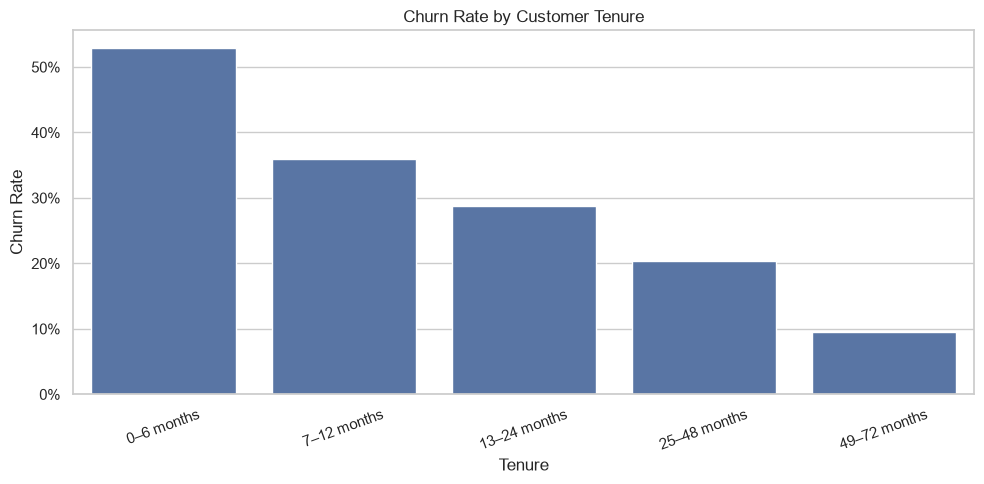

In [9]:
plot_data = tenure_analysis.reset_index()
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=plot_data, x="Tenure Band", y="churn_rate", ax=ax, color="C0")
ax.set_title("Churn Rate by Customer Tenure")
ax.set_xlabel("Tenure")
ax.set_ylabel("Churn Rate")
ax.yaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 9. Contract Type — A Key Retention Signal

Contract structure is compared using customer volume, churn rate, average monthly charge, and monthly charges at risk. This separates **rate-based risk** from **financial exposure**.

In [10]:
contract_analysis = (
    df.groupby("Contract")
      .agg(customers=("CustomerID", "count"),
           churned=("Churn Flag", "sum"),
           avg_monthly_charge=("Monthly Charges", "mean"),
           monthly_charges=("Monthly Charges", "sum"))
)
contract_analysis["churn_rate"] = contract_analysis["churned"] / contract_analysis["customers"]
contract_analysis["revenue_at_risk"] = (
    df[df["Churn Flag"].eq(1)]
    .groupby("Contract")["Monthly Charges"]
    .sum()
    .reindex(contract_analysis.index)
    .fillna(0)
)
display(contract_analysis.style.format({
    "churn_rate": "{:.1%}",
    "avg_monthly_charge": "${:,.2f}",
    "monthly_charges": "${:,.0f}",
    "revenue_at_risk": "${:,.0f}"
}))

,customers,churned,avg_monthly_charge,monthly_charges,churn_rate,revenue_at_risk
Contract,,,,,,
Month-to-month,3875,1655,$66.40,"$257,294",42.7%,"$120,847"
One year,1473,166,$65.05,"$95,817",11.3%,"$14,118"
Two year,1695,48,$60.77,"$103,006",2.8%,"$4,165"


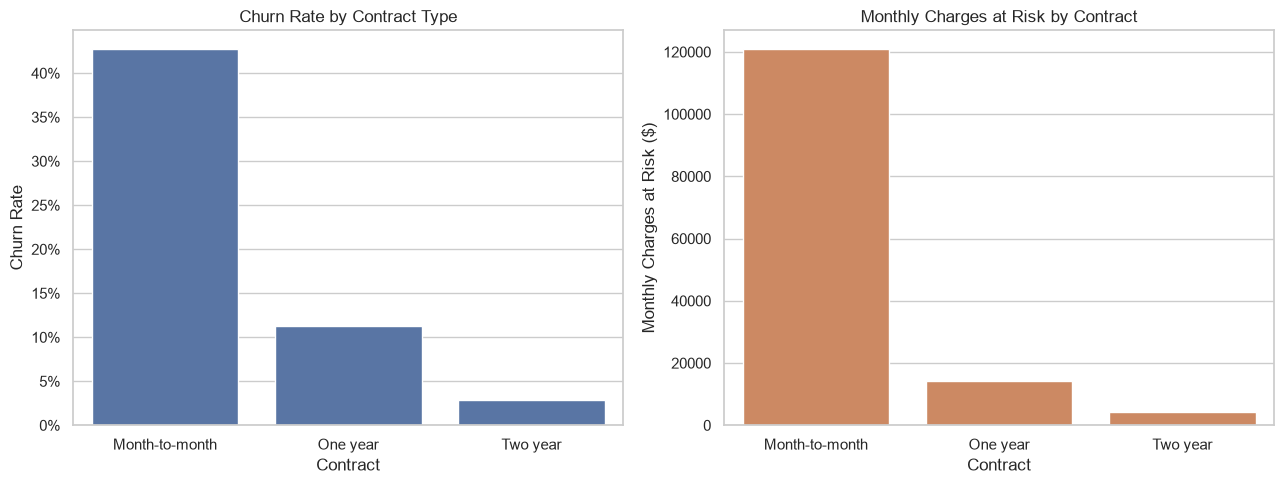

In [11]:
plot_contract = contract_analysis.reset_index()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=plot_contract, x="Contract", y="churn_rate", ax=axes[0], color="C0")
axes[0].set_title("Churn Rate by Contract Type")
axes[0].set_ylabel("Churn Rate")
axes[0].yaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
sns.barplot(data=plot_contract, x="Contract", y="revenue_at_risk", ax=axes[1], color="C1")
axes[1].set_title("Monthly Charges at Risk by Contract")
axes[1].set_ylabel("Monthly Charges at Risk ($)")
plt.tight_layout()
plt.show()

## 10. Service Adoption & Churn

Service configuration is analysed as a segmentation signal. Differences in churn rate are associations in the observed data; they should not be interpreted as proof that adding or removing a service causes churn.

In [12]:
service_cols = ["Internet Service", "Online Security", "Online Backup",
                "Device Protection", "Tech Support"]

service_results = []
for col in service_cols:
    temp = (
        df.groupby(col)
          .agg(customers=("CustomerID", "count"), churned=("Churn Flag", "sum"))
          .reset_index()
    )
    temp["churn_rate"] = temp["churned"] / temp["customers"]
    temp["feature"] = col
    temp = temp.rename(columns={col: "segment"})
    service_results.append(temp[["feature", "segment", "customers", "churned", "churn_rate"]])

service_analysis = pd.concat(service_results, ignore_index=True)
display(service_analysis.sort_values(["feature", "churn_rate"], ascending=[True, False])
        .style.format({"churn_rate": "{:.1%}"}))

,feature,segment,customers,churned,churn_rate
9,Device Protection,No,3095,1211,39.1%
11,Device Protection,Yes,2422,545,22.5%
10,Device Protection,No internet service,1526,113,7.4%
1,Internet Service,Fiber optic,3096,1297,41.9%
0,Internet Service,DSL,2421,459,19.0%
2,Internet Service,No,1526,113,7.4%
6,Online Backup,No,3088,1233,39.9%
8,Online Backup,Yes,2429,523,21.5%
7,Online Backup,No internet service,1526,113,7.4%
3,Online Security,No,3498,1461,41.8%


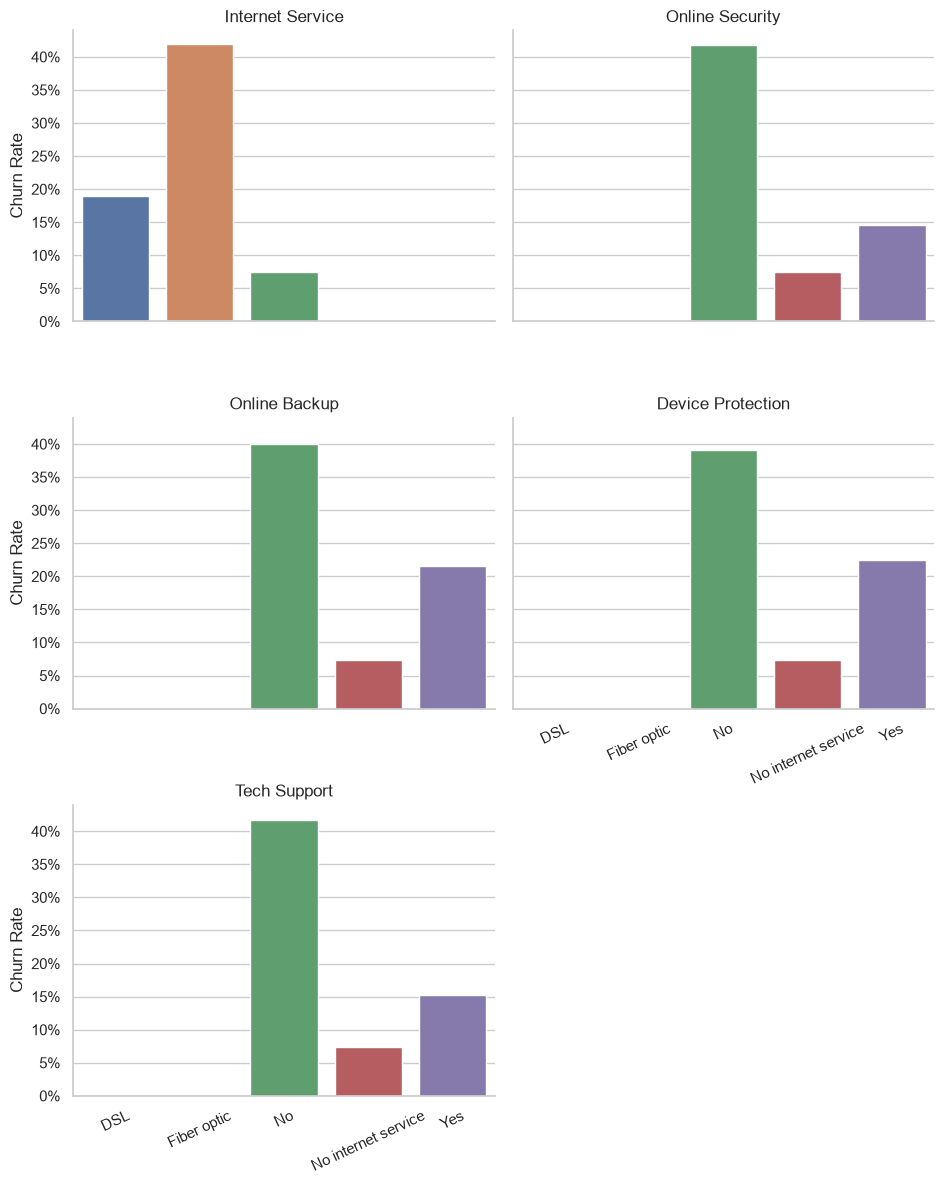

In [13]:
g = sns.catplot(
    data=service_analysis, x="segment", y="churn_rate",
    col="feature", col_wrap=2, kind="bar", height=4, aspect=1.2, palette="deep", hue="segment", legend=False
)
g.set_axis_labels("", "Churn Rate")
g.set_titles("{col_name}")
for ax in g.axes.flat:
    ax.yaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

## 11.1 Service Engagement Index

To create a more business-oriented customer view, we count how many optional digital/support services each customer has subscribed to.

This is not a causal feature. It is a simple engagement indicator that lets us compare churn across customers with different levels of service adoption.

In [14]:
service_binary = [
    "Online Security", "Online Backup", "Device Protection",
    "Tech Support", "Streaming TV", "Streaming Movies"
]

df["Service Engagement Count"] = 0

for col in service_binary:
    df["Service Engagement Count"] += df[col].eq("Yes").astype(int)

engagement_analysis = (
    df.groupby("Service Engagement Count")
      .agg(customers=("CustomerID", "count"),
           churned=("Churn Flag", "sum"),
           avg_monthly_charge=("Monthly Charges", "mean"))
)

engagement_analysis["churn_rate"] = (
    engagement_analysis["churned"] / engagement_analysis["customers"]
)

display(engagement_analysis.style.format({
    "churn_rate": "{:.1%}",
    "avg_monthly_charge": "${:,.2f}"
}))

,customers,churned,avg_monthly_charge,churn_rate
Service Engagement Count,,,,
0,2219,475,$32.79,21.4%
1,966,442,$65.57,45.8%
2,1033,370,$72.42,35.8%
3,1118,306,$80.11,27.4%
4,852,190,$87.77,22.3%
5,571,71,$92.18,12.4%
6,284,15,$99.37,5.3%


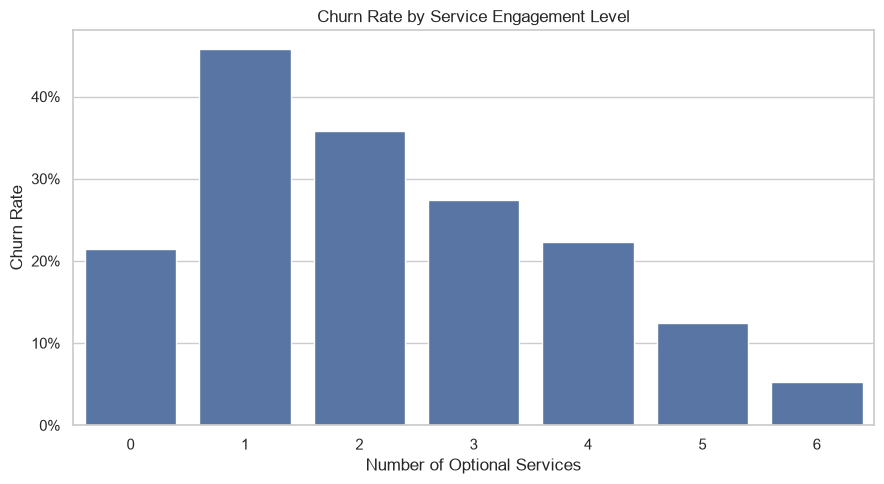

In [15]:
plot_engagement = engagement_analysis.reset_index()

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(
    data=plot_engagement,
    x="Service Engagement Count",
    y="churn_rate",
    ax=ax,
    color="C0"
)
ax.set_title("Churn Rate by Service Engagement Level")
ax.set_xlabel("Number of Optional Services")
ax.set_ylabel("Churn Rate")
ax.yaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
plt.tight_layout()
plt.show()

## 11. Demographic Segmentation

Gender, senior-citizen status, partner status, and dependent status are used to describe churn patterns. They are segmentation variables, not causal explanations.

In [16]:
demo_cols = ["Gender", "Senior Citizen", "Partner", "Dependents"]
demo_results = []

for col in demo_cols:
    temp = (
        df.groupby(col)
          .agg(customers=("CustomerID", "count"),
               churned=("Churn Flag", "sum"),
               monthly_charges=("Monthly Charges", "sum"))
          .reset_index()
    )
    temp["churn_rate"] = temp["churned"] / temp["customers"]
    temp["revenue_at_risk"] = (
        df[df["Churn Flag"].eq(1)]
        .groupby(col)["Monthly Charges"]
        .sum()
        .reindex(temp[col]).fillna(0).values
    )
    temp["feature"] = col
    temp = temp.rename(columns={col: "segment"})
    demo_results.append(temp)

demo_analysis = pd.concat(demo_results, ignore_index=True)
display(demo_analysis[["feature", "segment", "customers", "churn_rate", "revenue_at_risk"]]
        .style.format({"churn_rate": "{:.1%}", "revenue_at_risk": "${:,.0f}"}))

,feature,segment,customers,churn_rate,revenue_at_risk
0,Gender,Female,3488,26.9%,"$70,249"
1,Gender,Male,3555,26.2%,"$68,882"
2,Senior Citizen,No,5901,23.6%,"$100,711"
3,Senior Citizen,Yes,1142,41.7%,"$38,420"
4,Partner,No,3641,33.0%,"$85,741"
5,Partner,Yes,3402,19.7%,"$53,390"
6,Dependents,No,5416,32.6%,"$132,855"
7,Dependents,Yes,1627,6.5%,"$6,276"


## 12. Payment Behaviour

Payment method is compared by customer volume, churn rate, average monthly charge, and revenue exposure.

In [17]:
payment_analysis = (
    df.groupby("Payment Method")
      .agg(customers=("CustomerID", "count"),
           churned=("Churn Flag", "sum"),
           avg_monthly_charge=("Monthly Charges", "mean"))
)
payment_analysis["churn_rate"] = payment_analysis["churned"] / payment_analysis["customers"]
payment_analysis["revenue_at_risk"] = (
    df[df["Churn Flag"].eq(1)]
    .groupby("Payment Method")["Monthly Charges"]
    .sum()
    .reindex(payment_analysis.index).fillna(0)
)
display(payment_analysis.sort_values("churn_rate", ascending=False)
        .style.format({"churn_rate": "{:.1%}",
                       "avg_monthly_charge": "${:,.2f}",
                       "revenue_at_risk": "${:,.0f}"}))

,customers,churned,avg_monthly_charge,churn_rate,revenue_at_risk
Payment Method,,,,,
Electronic check,2365,1071,$76.26,45.3%,"$84,289"
Mailed check,1612,308,$43.92,19.1%,"$16,804"
Bank transfer (automatic),1544,258,$67.19,16.7%,"$20,092"
Credit card (automatic),1522,232,$66.51,15.2%,"$17,947"


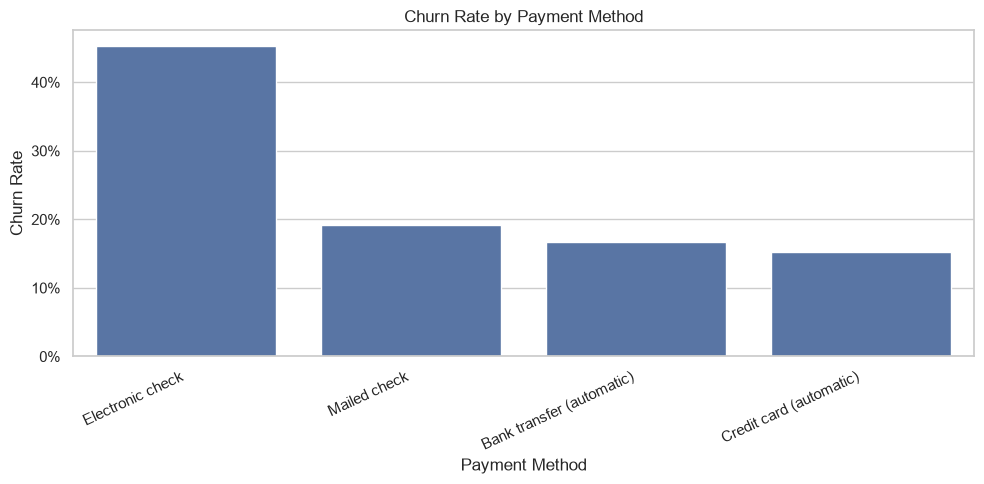

In [18]:
plot_payment = payment_analysis.reset_index().sort_values("churn_rate", ascending=False)
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=plot_payment, x="Payment Method", y="churn_rate", ax=ax, color="C0")
ax.set_title("Churn Rate by Payment Method")
ax.set_ylabel("Churn Rate")
ax.yaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 13. Geography — Data Coverage Check

The source extract contains geographic fields, but the `State` field has only one unique value in this dataset. That means a state-level comparison would be misleading because there is no cross-state variation to analyze.

Rather than inventing geographic conclusions, we explicitly document the limitation and focus the analysis on dimensions that contain meaningful variation.



In [19]:
state_count = df["State"].nunique(dropna=True)
city_count = df["City"].nunique(dropna=True)

print(f"Unique states in the dataset: {state_count}")
print(f"Unique cities in the dataset: {city_count}")

if state_count == 1:
    print("Geographic conclusion: state-level churn comparison is not meaningful for this extract because all customers belong to the same state.")


Unique states in the dataset: 1
Unique cities in the dataset: 1129
Geographic conclusion: state-level churn comparison is not meaningful for this extract because all customers belong to the same state.


## 14. Revenue Exposure

Retention teams should not prioritize segments solely because their churn rate is high. This section combines churn rate with recurring monthly-charge exposure.

**Churn rate** answers: how frequently are customers leaving?  
**Revenue at risk** answers: how much current monthly recurring charge is attached to those churned customers?

Contract,Month-to-month,One year,Two year
Tenure Band,,,
0–6 months,"$49,681",$215,$0
7–12 months,"$18,620",$438,$0
13–24 months,"$21,980","$1,101",$0
25–48 months,"$22,557","$4,521",$384
49–72 months,"$8,008","$7,843","$3,781"


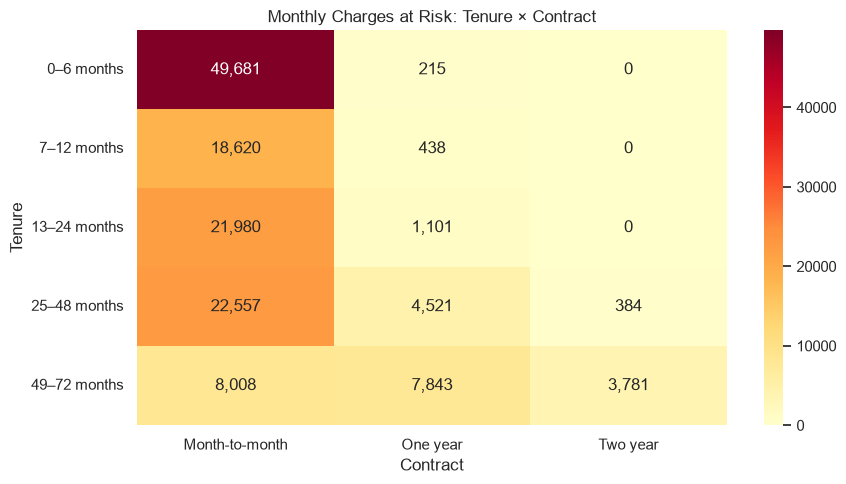

In [20]:
risk_matrix = pd.pivot_table(
    df[df["Churn Flag"].eq(1)],
    index="Tenure Band",
    columns="Contract",
    values="Monthly Charges",
    aggfunc="sum",
    fill_value=0
)
display(risk_matrix.style.format("${:,.0f}"))

fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(risk_matrix, annot=True, fmt=",.0f", cmap="YlOrRd", ax=ax)
ax.set_title("Monthly Charges at Risk: Tenure × Contract")
ax.set_xlabel("Contract")
ax.set_ylabel("Tenure")
plt.tight_layout()
plt.show()

## 15. Customer Value & Churn

Monthly charges, total charges, and tenure are compared between retained and churned customers. Total charges should be interpreted alongside tenure because longer-tenured customers naturally have more accumulated charges.

In [21]:
value_comparison = (
    df.groupby("Churn Label")
      .agg(customers=("CustomerID", "count"),
           avg_monthly_charge=("Monthly Charges", "mean"),
           median_monthly_charge=("Monthly Charges", "median"),
           avg_total_charges=("Total Charges", "mean"),
           avg_tenure=("Tenure Months", "mean"))
)
display(value_comparison.style.format({
    "avg_monthly_charge": "${:,.2f}",
    "median_monthly_charge": "${:,.2f}",
    "avg_total_charges": "${:,.2f}",
    "avg_tenure": "{:.1f}"
}))

,customers,avg_monthly_charge,median_monthly_charge,avg_total_charges,avg_tenure
Churn Label,,,,,
No,5174,$61.27,$64.43,"$2,555.34",37.6
Yes,1869,$74.44,$79.65,"$1,531.80",18.0


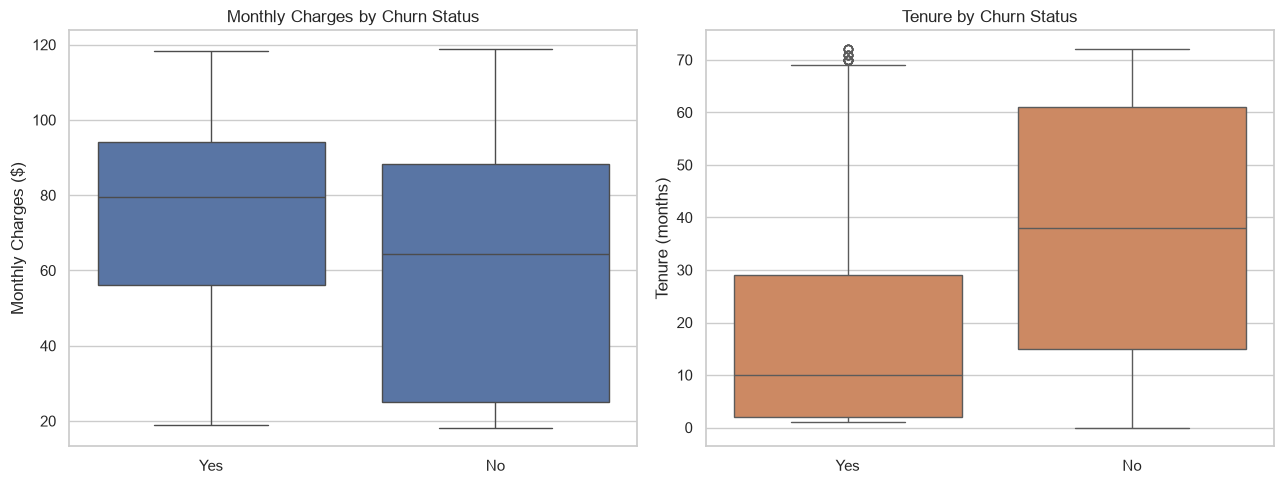

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=df, x="Churn Label", y="Monthly Charges", ax=axes[0], color="C0")
axes[0].set_title("Monthly Charges by Churn Status")
axes[0].set_xlabel("")
axes[0].set_ylabel("Monthly Charges ($)")
sns.boxplot(data=df, x="Churn Label", y="Tenure Months", ax=axes[1], color="C1")
axes[1].set_title("Tenure by Churn Status")
axes[1].set_xlabel("")
axes[1].set_ylabel("Tenure (months)")
plt.tight_layout()
plt.show()

## 16. Churn Reasons — Voice of the Churned Customer

`Churn Reason` is available for churned customers. It adds operational context to the segmentation analysis.

These are recorded customer-reported categories and should not be treated as experimentally proven causal factors.

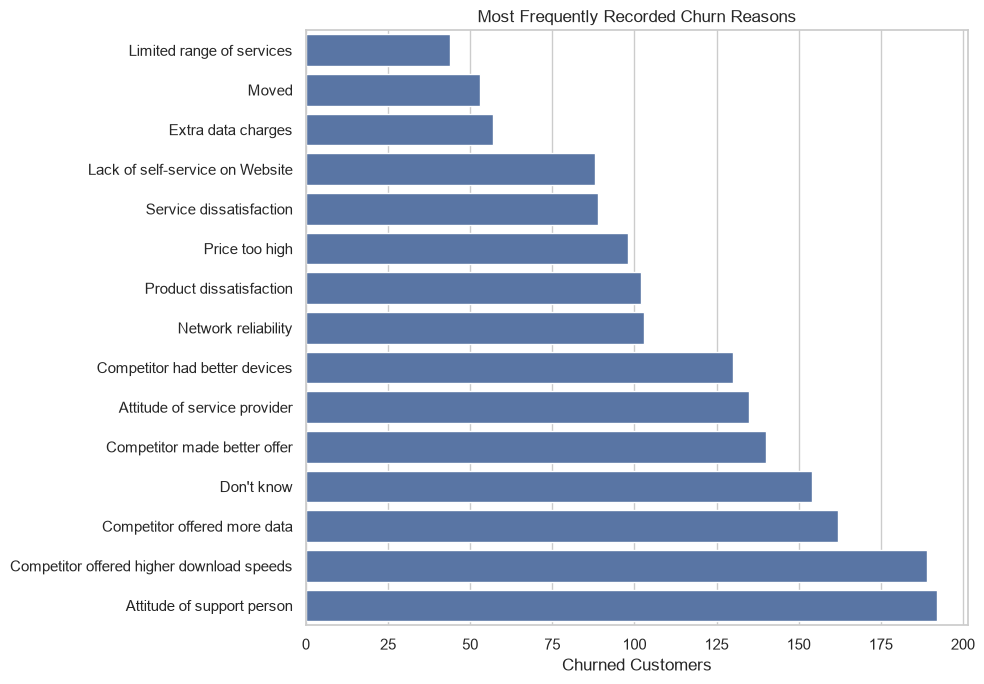

,customers
Churn Reason,
Attitude of support person,192
Competitor offered higher download speeds,189
Competitor offered more data,162
Don't know,154
Competitor made better offer,140
Attitude of service provider,135
Competitor had better devices,130
Network reliability,103
Product dissatisfaction,102


In [23]:
churn_reasons = (
    df[df["Churn Flag"].eq(1)]["Churn Reason"]
      .value_counts()
      .head(15)
      .sort_values()
)

fig, ax = plt.subplots(figsize=(10, 7))
sns.barplot(x=churn_reasons.values, y=churn_reasons.index, ax=ax, color="C0")
ax.set_title("Most Frequently Recorded Churn Reasons")
ax.set_xlabel("Churned Customers")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

display(churn_reasons.sort_values(ascending=False).to_frame("customers"))

## 17. SQL Business Analysis

The SQLite layer answers the same type of business questions using SQL aggregation. This demonstrates practical SQL alongside Python analytics.

In [24]:
sql_contract = pd.read_sql_query("""
SELECT
    Contract,
    COUNT(*) AS customers,
    SUM(CASE WHEN "Churn Label" = 'Yes' THEN 1 ELSE 0 END) AS churned_customers,
    ROUND(100.0 * SUM(CASE WHEN "Churn Label" = 'Yes' THEN 1 ELSE 0 END) / COUNT(*), 2) AS churn_rate_pct,
    ROUND(SUM(CASE WHEN "Churn Label" = 'Yes' THEN "Monthly Charges" ELSE 0 END), 2) AS monthly_revenue_at_risk
FROM customers
GROUP BY Contract
ORDER BY churn_rate_pct DESC;
""", conn)
display(sql_contract)

,Contract,customers,churned_customers,churn_rate_pct,monthly_revenue_at_risk
0,Month-to-month,3875,1655,42.71,"120,847.10"
1,One year,1473,166,11.27,"14,118.45"
2,Two year,1695,48,2.83,"4,165.30"


In [25]:
sql_tenure = pd.read_sql_query("""
SELECT
    "Tenure Band",
    COUNT(*) AS customers,
    SUM("Churn Flag") AS churned_customers,
    ROUND(AVG("Churn Flag") * 100, 2) AS churn_rate_pct,
    ROUND(SUM("Revenue at Risk"), 2) AS monthly_revenue_at_risk
FROM customers
GROUP BY "Tenure Band"
ORDER BY CASE "Tenure Band"
    WHEN '0–6 months' THEN 1
    WHEN '7–12 months' THEN 2
    WHEN '13–24 months' THEN 3
    WHEN '25–48 months' THEN 4
    WHEN '49–72 months' THEN 5
END;
""", conn)
display(sql_tenure)

,Tenure Band,customers,churned_customers,churn_rate_pct,monthly_revenue_at_risk
0,0–6 months,1481,784,52.94,"49,896.10"
1,7–12 months,705,253,35.89,"19,058.15"
2,13–24 months,1024,294,28.71,"23,081.65"
3,25–48 months,1594,325,20.39,"27,462.50"
4,49–72 months,2239,213,9.51,"19,632.45"


## 18. Customer-Level Revenue Concentration

Not all customers have the same financial importance. This view ranks customers by current monthly charge and measures how concentrated recurring revenue is among higher-value accounts.

In [26]:
customer_value = (
    df[["CustomerID", "Monthly Charges", "Total Charges", "Tenure Months", "Churn Label"]]
    .sort_values("Monthly Charges", ascending=False)
    .copy()
)
customer_value["monthly_revenue_share"] = customer_value["Monthly Charges"] / customer_value["Monthly Charges"].sum()
customer_value["cumulative_revenue_share"] = customer_value["monthly_revenue_share"].cumsum()

top_10_pct_n = max(1, int(np.ceil(len(customer_value) * 0.10)))
top_10_pct_revenue_share = (
    customer_value.head(top_10_pct_n)["Monthly Charges"].sum()
    / customer_value["Monthly Charges"].sum()
)

print(f"Top 10% of customers account for approximately {top_10_pct_revenue_share:.1%} of current monthly charges.")
display(customer_value.head(10))

Top 10% of customers account for approximately 16.7% of current monthly charges.


,CustomerID,Monthly Charges,Total Charges,Tenure Months,Churn Label,monthly_revenue_share,cumulative_revenue_share
5251,7569-NMZYQ,118.75,"8,672.45",72,No,0.00,0.00
3422,8984-HPEMB,118.65,"8,477.60",71,No,0.00,0.00
5417,5734-EJKXG,118.60,"7,365.70",61,No,0.00,0.00
4736,5989-AXPUC,118.60,"7,990.05",68,No,0.00,0.00
1347,8199-ZLLSA,118.35,"7,804.15",67,Yes,0.00,0.00
6372,9924-JPRMC,118.20,"8,547.15",72,No,0.00,0.00
1206,2889-FPWRM,117.80,"8,684.80",72,Yes,0.00,0.00
4235,3810-DVDQQ,117.60,"8,308.90",72,No,0.00,0.00
6850,9739-JLPQJ,117.50,"8,670.10",72,No,0.00,0.00
1275,2302-ANTDP,117.45,"5,438.90",48,Yes,0.00,0.00


## 19. Churn Driver Comparison

The following tables summarize selected segments by churn rate. A high rate is treated as a signal for further investigation, not proof that the segment characteristic causes churn.

The most useful retention opportunities are segments where elevated churn overlaps with meaningful customer volume and/or recurring revenue exposure.

In [27]:
driver_tables = {
    "Contract": df.groupby("Contract").agg(customers=("CustomerID", "count"), churn_rate=("Churn Flag", "mean")),
    "Internet Service": df.groupby("Internet Service").agg(customers=("CustomerID", "count"), churn_rate=("Churn Flag", "mean")),
    "Payment Method": df.groupby("Payment Method").agg(customers=("CustomerID", "count"), churn_rate=("Churn Flag", "mean")),
    "Tenure Band": df.groupby("Tenure Band", observed=True).agg(customers=("CustomerID", "count"), churn_rate=("Churn Flag", "mean"))
}
for name, table in driver_tables.items():
    print(f"### {name}")
    display(table.sort_values("churn_rate", ascending=False).style.format({"churn_rate": "{:.1%}"}))

### Contract


,customers,churn_rate
Contract,,
Month-to-month,3875,42.7%
One year,1473,11.3%
Two year,1695,2.8%


### Internet Service


,customers,churn_rate
Internet Service,,
Fiber optic,3096,41.9%
DSL,2421,19.0%
No,1526,7.4%


### Payment Method


,customers,churn_rate
Payment Method,,
Electronic check,2365,45.3%
Mailed check,1612,19.1%
Bank transfer (automatic),1544,16.7%
Credit card (automatic),1522,15.2%


### Tenure Band


,customers,churn_rate
Tenure Band,,
0–6 months,1481,52.9%
7–12 months,705,35.9%
13–24 months,1024,28.7%
25–48 months,1594,20.4%
49–72 months,2239,9.5%


## 20. Key Business Findings

### 1 — The customer base has a 26.5% churn rate
Out of 7,043 customers, 1,869 are labelled as churned, while 5,174 are retained. The overall retention rate is 73.5%.

### 2 — Churn is heavily concentrated in the early lifecycle
Customers with 0–6 months of tenure have a **52.9% churn rate**, compared with **9.5%** among customers with 49–72 months of tenure. This is the clearest lifecycle signal in the dataset.

### 3 — Contract type is strongly associated with retention
Month-to-month customers have a **42.7% churn rate**, compared with **11.3%** for one-year contracts and **2.8%** for two-year contracts. Month-to-month churn also represents approximately **$120.8K of the $139.1K monthly charges at risk**.

### 4 — Internet service and payment method show strong segmentation differences
Fiber-optic customers have a **41.9% churn rate**, compared with 19.0% for DSL and 7.4% for customers without internet service. Electronic-check customers have a **45.3% churn rate**, the highest among payment methods.

These are associations in the observed customer base, not proof that a service or payment method causes churn.

### 5 — Support and security services are useful retention signals
Customers' optional service configurations show materially different churn rates. A service-engagement view can therefore be used to identify segments for further investigation and targeted customer-experience experiments.

### 6 — Revenue exposure should be considered alongside churn rate
The dataset contains **$456.1K in current monthly charges**, of which **$139.1K is attached to customers labelled as churned**. This exposure is not a lifetime-revenue forecast, but it gives a practical scale for retention prioritization.

### 7 — Customer-reported churn reasons provide operational direction
The most frequently recorded reasons include competitor offers, support/service experience, network reliability, product dissatisfaction, and pricing-related concerns. These themes can be translated into specific retention hypotheses.

### 8 — Geographic conclusions should not be generalized
The provided extract contains only one unique state value, so state-level comparisons are not meaningful. The analysis therefore avoids presenting a misleading geographic ranking.


## 21. Recommended Retention Actions

### 1. Strengthen early-lifecycle onboarding
Introduce proactive onboarding, service education and early satisfaction checks for newer customers.

### 2. Encourage longer-term relationships
Where commercially appropriate, test incentives that help suitable short-term customers move toward longer-term contracts.

### 3. Build service-engagement interventions
Use targeted education, bundles or support outreach for customers with service configurations associated with elevated churn.

### 4. Prioritize revenue-weighted retention
Combine churn rate with monthly charges at risk when selecting segments for immediate retention investment.

### 5. Respond to competitive pressure
Competitive-offer churn reasons suggest monitoring pricing, product positioning, service quality and competitor propositions.

### 6. Close the customer-feedback loop
Use recorded churn reasons to feed customer-experience improvement initiatives and measure whether targeted changes reduce future churn.

## 22. Limitations & Analytical Cautions

- The dataset represents a customer snapshot rather than a continuously observed cohort.
- Observational relationships do not prove causation.
- `Churn Score` and `CLTV` are source-derived fields and are excluded from explanatory driver analysis.
- Customer-reported churn reasons are recorded categories, not experimental causal evidence.
- Monthly revenue at risk represents current monthly charges of churned customers; it is not a lifetime-revenue forecast.
- Marketing touches, discounts, acquisition costs, service-quality measures and competitor pricing are not available.
- Geographic analysis is kept at an aggregate level.

## 23. Final Conclusion

Customer retention is not a single-variable problem. The analysis shows that churn should be viewed through several complementary lenses: **customer lifecycle, contract structure, service configuration, payment behaviour, customer characteristics, and financial exposure**.

A practical retention strategy should therefore identify **high-risk and high-value segments**, understand the recorded reasons behind churn, and test targeted interventions across onboarding, contract conversion, service engagement, pricing and customer experience.

This project demonstrates an end-to-end analytics workflow using **Python, Pandas, NumPy, Matplotlib, Seaborn and SQLite**, with a focus on translating customer data into practical business decisions.